# Weather-downtime climatology for the scheduler simulations (record)

> **Status: record.** The long-baseline weather-downtime fraction below was forwarded to the Scheduler team in
> October 2026 and evaluated there. This notebook keeps the derivation so the numbers can be traced; it is not an open
> recommendation, and it is not part of the ROSP-11 time-loss accounting.

Moved on 2026-11-06 from lsst/sp_notebooks ROSP-11 diagnostics (PR #29 review): §1–3 were §5 of
[`weather_downtime_analysis.ipynb`](https://github.com/lsst/sp_notebooks/blob/main/tracking_hub/ops/rosp-11_time_loss_accounting/weather_downtime_analysis.ipynb), §4 was §7 of
[`allsky_cloud_analysis.ipynb`](https://github.com/lsst/sp_notebooks/blob/main/tracking_hub/ops/rosp-11_time_loss_accounting/allsky_cloud_analysis.ipynb). Section references of the form "downtime
notebook §N" point to the downtime notebook's current layout (§4.1 flag calibration, §3 night attribution); the
allskycam validation against LSSTCam zero points and DREAM is in the allskycam notebook's §2.2 and §3.1.

**Inputs** (under `SYSTEM_PERFORMANCE_DATA_DIR`, default `/sdf/data/rubin/user/stalder/system_performance_data`):
`weather_proxy_nightly_2019_2026.parquet` and `allskycam_gated_nightly.parquet` (written by the downtime notebook
with `ROSP11_WRITE_RESULTS=1`), `nightly_attribution_20250415_20260713.parquet` (same), `ctio_clouds_1975_2022.parquet`
(`build_log_cache.py`), and the allskycam nightly table `index/allsky_nightly.parquet` under `ALLSKY_OUT`.
**Outputs** (only with `ROSP11_WRITE_RESULTS=1`): `weather_downtime_monthly_climatology.csv`, which the allskycam
notebook's §5 reads, and `weather_downtime_climatology_results.json`.


In [1]:
import json, os, pathlib, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
DATA = pathlib.Path(
    os.environ.get(
        "SYSTEM_PERFORMANCE_DATA_DIR",
        "/sdf/data/rubin/user/stalder/system_performance_data",
    )
)
A = pathlib.Path(os.environ.get("ALLSKY_OUT", "/sdf/data/rubin/user/stalder/allsky"))
WRITE_RESULTS = os.environ.get("ROSP11_WRITE_RESULTS", "0") == "1"
DAY0, DAY1 = 20250415, 20260713  # LSSTCam window of the downtime notebook (inclusive)
FLAG_START = 20260225  # first night with Scheduler observatoryStatus
CAM_T = 0.3  # allskycam cloud index treated as "cloudy"

P = dict(
    blue="#2a78d6",
    orange="#eb6834",
    aqua="#1baf7a",
    yellow="#eda100",
    magenta="#e87ba4",
    green="#008300",
    violet="#4a3aa7",
    red="#e34948",
)
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
mpl.rcParams.update(
    {
        "figure.facecolor": SURF,
        "axes.facecolor": SURF,
        "axes.edgecolor": GRID,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 1,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": INK2,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "text.color": INK,
        "axes.titlecolor": INK,
        "axes.titlelocation": "left",
        "axes.titleweight": "semibold",
        "font.size": 10,
        "lines.linewidth": 2,
        "figure.dpi": 110,
    }
)

proxy = pd.read_parquet(DATA / "weather_proxy_nightly_2019_2026.parquet")
camn = pd.read_parquet(DATA / "allskycam_gated_nightly.parquet")
nights = pd.read_parquet(DATA / "nightly_attribution_20250415_20260713.parquet")
N = pd.read_parquet(A / "index/allsky_nightly.parquet")
print(
    f"EFD proxy {len(proxy)} nights, allskycam {len(camn)} nights, attribution {len(nights)} nights, "
    f"allskycam nightly table {len(N)} nights"
)

EFD proxy 1787 nights, allskycam 1690 nights, attribution 455 nights, allskycam nightly table 1690 nights


## 1. Long-baseline weather downtime: the baselines

Four baselines, each giving a **nightly fraction of dark time lost to weather**:

| baseline | span | what it measures |
|---|---|---|
| **Scheduler WEATHER flag** | 2026-02-25 → 07-13 (4.5 months, austral autumn/winter only) | the operational truth, but seasonally biased |
| **Allskycam** (cloud index > 0.3, and > 0.5) | 2021-07 → 2026-10 (1541 nights with ≥ 80 % frame coverage that pass the astrometric gate) | the measured sky, validated against the flag (downtime notebook §4.1) and LSSTCam photometry (allskycam notebook §2.2); the humidity / dew-point / wind limits are added where the EFD overlaps (1134 nights) |
| **EFD proxy** (limits ∪ cloud nowcast > 70 %) | 2023-03 → 2026-07 (827 nights with full coverage; limits-only back to 2019-12, 1581 nights) | the previous estimate, kept for comparison |
| **CTIO cloud database** (`clouds_ctio_1975_2022.db`, cloud > 0.3 = the `ModelObservatory` default `cloud_limit`) | 1975 → 2022, 17 414 nights | what the scheduler simulations assume today |

Note that `rubin_scheduler.site_models.UnscheduledDowntimeData` models *hardware* downtime only; weather enters the simulations exclusively through the cloud database, with no wind/humidity model (the default `wind_data` is "no wind").

In [2]:
pv = proxy[proxy.valid_full].copy()
pv["month"] = pv.index.astype(str).str[4:6].astype(int)
pv["year"] = pv.index.astype(str).str[:4].astype(int)
pl = proxy[proxy.valid_lim].copy()
pl["month"] = pl.index.astype(str).str[4:6].astype(int)
pl["year"] = pl.index.astype(str).str[:4].astype(int)
cl = pd.read_parquet(DATA / "ctio_clouds_1975_2022.parquet")
cl["bad"] = cl.cloud > 0.3
cl["night"] = (cl.t - pd.Timedelta(hours=16)).dt.date  # local night key
cn = cl.groupby("night").agg(
    bad=("bad", "mean"),
    month=("t", lambda s: s.iloc[0].month),
    year=("t", lambda s: s.iloc[0].year),
)
sf = nights.loc[FLAG_START:DAY1].dropna(subset=["W_h"])
sf = sf[sf.D_h < 0.5 * sf.night_h]
sf_frac = sf.W_h / (sf.night_h - sf.D_h)
clim = pd.DataFrame(
    {
        "Scheduler WEATHER 2026": sf_frac.groupby(
            sf.index.astype(str).str[4:6].astype(int)
        ).mean(),
        "EFD proxy 2023–26 (limits ∪ cloud>70)": pv.groupby("month").bad_frac.mean(),
        "EFD limits only 2019–26 (RH/Td/wind)": pl.groupby("month").lim_frac.mean(),
        "CTIO clouds 1975–2022 (cloud>0.3)": cn.groupby("month").bad.mean(),
        f"Allskycam 2021–26 (index>{CAM_T})": camn[camn.cam_valid]
        .groupby("month")
        .cam_frac.mean(),
        "Allskycam 2021–26 (index>0.5)": camn[camn.cam_valid]
        .groupby("month")
        .cam_frac50.mean(),
        f"Allskycam ∪ limits 2021–26 (index>{CAM_T})": proxy[proxy.valid_cam_full]
        .assign(month=lambda d: d.index.astype(str).str[4:6].astype(int))
        .groupby("month")
        .bad_cam_frac.mean(),
    }
).reindex(range(1, 13))
clim.index.name = "month"
pc = proxy[proxy.valid_cam_full].copy()
pc["month"] = pc.index.astype(str).str[4:6].astype(int)
pc["year"] = pc.index.astype(str).str[:4].astype(int)
cv = camn[camn.cam_valid]
clim.round(3)

,Scheduler WEATHER 2026,EFD proxy 2023–26 (limits ∪ cloud>70),EFD limits only 2019–26 (RH/Td/wind),CTIO clouds 1975–2022 (cloud>0.3),Allskycam 2021–26 (index>0.3),Allskycam 2021–26 (index>0.5),Allskycam ∪ limits 2021–26 (index>0.3)
month,,,,,,,
1,NaN,0.021,0.022,0.099,0.020,0.011,0.029
2,0.000,0.053,0.022,0.080,0.027,0.017,0.043
3,0.028,0.045,0.029,0.122,0.025,0.018,0.045
4,0.024,0.135,0.037,0.239,0.094,0.086,0.120
5,0.144,0.206,0.063,0.418,0.214,0.162,0.237
6,0.254,0.396,0.163,0.432,0.351,0.306,0.389
7,0.208,0.213,0.115,0.417,0.281,0.242,0.274
8,NaN,0.347,0.176,0.361,0.295,0.259,0.373
9,NaN,0.139,0.037,0.337,0.163,0.137,0.132


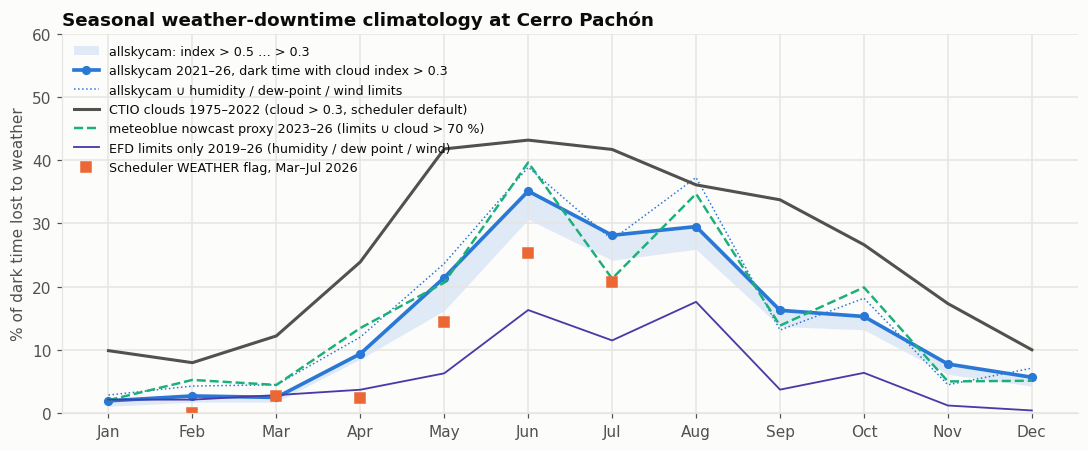

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
mo = np.arange(1, 13)
C = clim.columns
ax.fill_between(
    mo,
    clim[C[5]] * 100,
    clim[C[4]] * 100,
    color=P["blue"],
    alpha=0.13,
    lw=0,
    label="allskycam: index > 0.5 … > 0.3",
)
ax.plot(
    mo,
    clim[C[4]] * 100,
    color=P["blue"],
    lw=2.4,
    marker="o",
    ms=5,
    label=f"allskycam 2021–26, dark time with cloud index > {CAM_T}",
)
ax.plot(
    mo,
    clim[C[6]] * 100,
    color=P["blue"],
    lw=1,
    ls=":",
    label="allskycam ∪ humidity / dew-point / wind limits",
)
ax.plot(
    mo,
    clim[C[3]] * 100,
    color=INK2,
    lw=2,
    label="CTIO clouds 1975–2022 (cloud > 0.3, scheduler default)",
)
ax.plot(
    mo,
    clim[C[1]] * 100,
    color=P["aqua"],
    lw=1.6,
    ls="--",
    label="meteoblue nowcast proxy 2023–26 (limits ∪ cloud > 70 %)",
)
ax.plot(
    mo,
    clim[C[2]] * 100,
    color=P["violet"],
    lw=1.2,
    label="EFD limits only 2019–26 (humidity / dew point / wind)",
)
ax.plot(
    mo,
    clim[C[0]] * 100,
    color=P["orange"],
    lw=0,
    marker="s",
    ms=7,
    label="Scheduler WEATHER flag, Mar–Jul 2026",
)
ax.set_xticks(mo)
ax.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
ax.set_ylabel("% of dark time lost to weather")
ax.set_title("Seasonal weather-downtime climatology at Cerro Pachón")
ax.legend(frameon=False, fontsize=8.3, loc="upper left")
ax.set_ylim(0, 60)
plt.tight_layout()

## 2. Headline statistics

Nightly fraction of dark time lost to weather (per-night distribution and the annual mean). Every series is weighted so each calendar month counts equally (allskycam and proxy coverage is uneven); the nightly standard deviation is the raw per-night spread. The year-to-year spread is estimated the same way for every series, as the standard deviation over years of the mean monthly anomaly against the series' own monthly climatology (months with ≥ 10 nights, years with ≥ 6 such months), so that partial years can be used; for CTIO this reproduces the plain standard deviation of its 48 complete years.

In [4]:
def stats(frac_by_night, months):
    m = pd.Series(months, index=frac_by_night.index)
    eq = frac_by_night.groupby(m).mean().reindex(range(1, 13))
    return dict(
        nights=len(frac_by_night),
        mean_equal_month=eq.mean(),
        mean_raw=frac_by_night.mean(),
        median=frac_by_night.median(),
        std_nightly=frac_by_night.std(),
        frac_nights_fully_lost=(frac_by_night > 0.9).mean(),
        frac_nights_partial=((frac_by_night > 0.1) & (frac_by_night <= 0.9)).mean(),
        frac_nights_clear=(frac_by_night <= 0.1).mean(),
    )


def annual_spread(frac, years, months, min_nights=10, min_months=6):
    """Year-to-year std of the annual fraction, from each year's mean monthly anomaly vs the series' own monthly climatology (months with ≥ min_nights nights; years with ≥ min_months such months). Robust to uneven coverage."""
    d = pd.DataFrame(
        dict(f=np.asarray(frac), y=np.asarray(years), m=np.asarray(months))
    )
    mm = d.groupby(["y", "m"]).f.agg(["mean", "size"])
    mm = mm[mm["size"] >= min_nights]
    clim_m = mm["mean"].groupby(level=1).mean()
    an = (
        (mm["mean"] - clim_m.reindex(mm.index.get_level_values(1)).values)
        .groupby(level=0)
        .mean()
    )
    an = an[mm.groupby(level=0).size() >= min_months]
    return float(an.std()), int(len(an))


yr = cn.groupby("year").bad.mean()
cam_yr = cv.groupby("year").agg(
    nights=("cam_frac", "size"),
    frac=("cam_frac", "mean"),
    frac50=("cam_frac50", "mean"),
)
head = pd.DataFrame(
    {
        "Scheduler WEATHER flag (Mar–Jul 2026 only)": stats(
            sf_frac, sf.index.astype(str).str[4:6].astype(int)
        ),
        f"Allskycam 2021–26 (index>{CAM_T})": stats(cv.cam_frac, cv.month),
        "Allskycam 2021–26 (index>0.5)": stats(cv.cam_frac50, cv.month),
        f"Allskycam ∪ limits 2021–26 (index>{CAM_T})": stats(pc.bad_cam_frac, pc.month),
        f"Allskycam, LSSTCam window 2025-04→2026-07 (index>{CAM_T})": stats(
            cv.loc[DAY0:DAY1].cam_frac, cv.loc[DAY0:DAY1].month
        ),
        "Nowcast proxy 2023–26 (limits ∪ cloud>70)": stats(pv.bad_frac, pv.month),
        "Nowcast proxy, LSSTCam window": stats(
            pv.loc[DAY0:DAY1].bad_frac, pv.loc[DAY0:DAY1].month
        ),
        "CTIO clouds 1975–2022 (sim default)": stats(cn.bad, cn.month),
    }
).T
sp = [
    (np.nan, 0),
    annual_spread(cv.cam_frac, cv.year, cv.month),
    annual_spread(cv.cam_frac50, cv.year, cv.month),
    annual_spread(pc.bad_cam_frac, pc.year, pc.month),
    (np.nan, 0),
    annual_spread(pv.bad_frac, pv.year, pv.month),
    (np.nan, 0),
    annual_spread(cn.bad, cn.year, cn.month),
]
head["annual_std_across_years"] = [s[0] for s in sp]
head["years_in_annual_std"] = [s[1] for s in sp]
print(
    f"CTIO: plain std of the 48 complete-year means = {yr.std():.3f} (the month-anomaly estimator gives {sp[-1][0]:.3f})"
)
print("allskycam by year:")
print(cam_yr.round(3).T.to_string())
head.round(3)

CTIO: plain std of the 48 complete-year means = 0.049 (the month-anomaly estimator gives 0.049)
allskycam by year:
year       2021     2022     2023     2024     2025     2026
nights  150.000  287.000  304.000  243.000  346.000  218.000
frac      0.099    0.126    0.180    0.119    0.126    0.177
frac50    0.076    0.104    0.154    0.102    0.104    0.148


,nights,mean_equal_month,mean_raw,median,std_nightly,frac_nights_fully_lost,frac_nights_partial,frac_nights_clear,annual_std_across_years,years_in_annual_std
Scheduler WEATHER flag (Mar–Jul 2026 only),118.0,0.110,0.114,0.0,0.277,0.059,0.127,0.814,NaN,0
Allskycam 2021–26 (index>0.3),1548.0,0.147,0.140,0.0,0.287,0.063,0.182,0.755,0.048,6
Allskycam 2021–26 (index>0.5),1548.0,0.123,0.117,0.0,0.266,0.050,0.158,0.793,0.046,6
Allskycam ∪ limits 2021–26 (index>0.3),1134.0,0.162,0.148,0.0,0.289,0.066,0.198,0.735,0.031,5
"Allskycam, LSSTCam window 2025-04→2026-07 (index>0.3)",446.0,0.125,0.146,0.0,0.287,0.061,0.213,0.726,NaN,0
Nowcast proxy 2023–26 (limits ∪ cloud>70),827.0,0.155,0.163,0.0,0.319,0.088,0.164,0.747,0.043,3
"Nowcast proxy, LSSTCam window",410.0,0.116,0.133,0.0,0.283,0.059,0.166,0.776,NaN,0
CTIO clouds 1975–2022 (sim default),17414.0,0.254,0.255,0.0,0.384,0.158,0.201,0.641,0.049,48


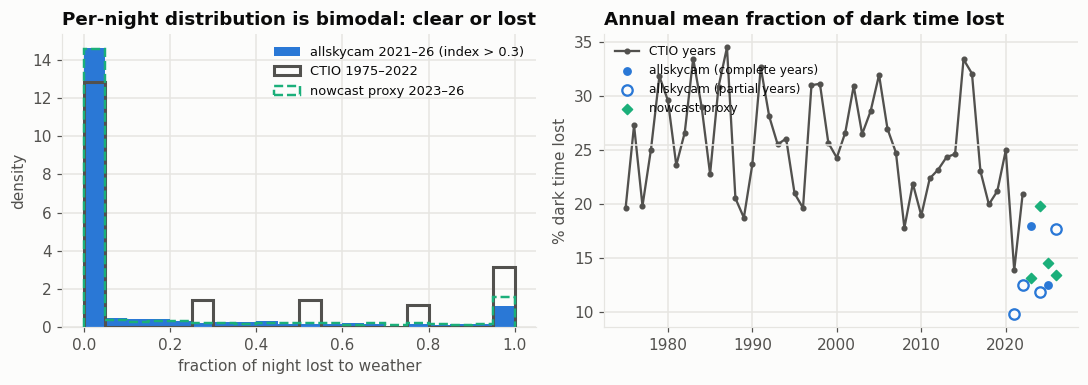

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
bins = np.linspace(0, 1, 21)
axes[0].hist(
    cv.cam_frac,
    bins=bins,
    color=P["blue"],
    zorder=2,
    density=True,
    label=f"allskycam 2021–26 (index > {CAM_T})",
)
axes[0].hist(
    cn.bad,
    bins=bins,
    histtype="step",
    color=INK2,
    lw=2,
    zorder=3,
    density=True,
    label="CTIO 1975–2022",
)
axes[0].hist(
    pv.bad_frac,
    bins=bins,
    histtype="step",
    color=P["aqua"],
    lw=1.6,
    ls="--",
    zorder=3,
    density=True,
    label="nowcast proxy 2023–26",
)
axes[0].set_xlabel("fraction of night lost to weather")
axes[0].set_ylabel("density")
axes[0].legend(frameon=False, fontsize=8.5)
axes[0].set_title("Per-night distribution is bimodal: clear or lost")
axes[1].plot(
    yr.index, yr.values * 100, color=INK2, lw=1.5, marker="o", ms=3, label="CTIO years"
)
axes[1].scatter(
    cam_yr.index[cam_yr.nights >= 300],
    cam_yr.frac[cam_yr.nights >= 300] * 100,
    color=P["blue"],
    s=46,
    zorder=5,
    edgecolor=SURF,
    label="allskycam (complete years)",
)
axes[1].scatter(
    cam_yr.index[cam_yr.nights < 300],
    cam_yr.frac[cam_yr.nights < 300] * 100,
    color=P["blue"],
    s=46,
    zorder=5,
    facecolor=SURF,
    linewidth=1.5,
    label="allskycam (partial years)",
)
pyr = pv.groupby("year").bad_frac.mean()
axes[1].scatter(
    pyr.index,
    pyr.values * 100,
    color=P["aqua"],
    s=22,
    zorder=4,
    marker="D",
    label="nowcast proxy",
)
axes[1].axhline(yr.mean() * 100, color=GRID, lw=1)
axes[1].set_ylabel("% dark time lost")
axes[1].set_title("Annual mean fraction of dark time lost")
axes[1].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()

## 3. Inputs forwarded for the scheduler simulations

> **Revised 2026-10-04 with the allskycam, 2026-10-11 with the v5 re-reduction, and 2026-10-28 with the allskycam nights to 2026-10-27.** The earliest version of this section rested on the meteoblue nowcast proxy and recommended 0.155; the allskycam shows the nowcast misses thin and broken cloud (downtime notebook §4.1, §4.3). The 2026-10-04 version used the v3 reduction and recommended 0.17 / 0.13; v5 removed false cloud from camera-swap months and from soft-focus epochs, and the numbers below are for v5. The 2026-10-28 update adds the cloudy October 2026 nights: the annual mean goes from 0.143 to 0.146 and the year-to-year spread from 0.04 to 0.05.

* **Point estimate:** the allskycam gives **≈ 0.15 of dark time with unusable sky** (equal-month annual mean 0.146 at cloud index > 0.3; 0.16 with the humidity / dew-point / wind limits added), with **≈ 6 % of nights fully lost, ≈ 18 % partially affected, ≈ 76 % clear**. At the stricter index > 0.5, which matches the operators' flagged hours to within 7 % and is where κ against the flag peaks (downtime notebook §4.1), it gives **0.12**. Over the LSSTCam window itself (Apr 2025 → Jul 2026) the allskycam gives 0.13 (equal-month; 0.16 of dark hours by direct accounting), and the whole-night accounting of the downtime notebook's §3 gives ≈ 18 % of all dark hours (57 fully-lost weather nights ≈ 13.3 %, partial losses on observed nights ≈ 5 %; whole-night accounting rounds every > 50 % night up to a full loss and so leans high). **Recommended central value: 0.15 at the allskycam's "stars not detectable" threshold, 0.12 at the operators' de-facto closing threshold, with a ± 0.05 year-to-year spread.** Use the allskycam monthly table (`weather_downtime_monthly_climatology.csv`, both thresholds), not a single number.
* **Seasonality dominates:** Jun ≈ 35 %, Aug ≈ 30 %, Jul ≈ 28 %, May ≈ 22 %, Sep ≈ 16 %, Oct ≈ 16 %, Jan–Mar ≈ 2–3 %. The secondary February peak of the v3 record (≈ 11 %) was the February 2023 camera-swap artefact and is gone. The *per-night* standard deviation (≈ 0.29) reflects the clear-or-lost bimodality rather than a Gaussian spread.
* **Year-to-year:** the six allskycam years (2021–26) span 0.10–0.18 (2021 low, 2023 and the partial 2026 high) with a month-anomaly standard deviation of ≈ 0.05 (0.04 before October 2026 was added); the CTIO record's 48 years give 0.05 around a mean of 0.25. A ± 0.05 annual spread is the appropriate input; six years do not resolve whether the Rubin era is intrinsically less variable or merely short.
* **The scheduler's default CTIO cloud model is ≈ 11 percentage points more pessimistic** than the Rubin record (0.25 vs 0.15 equal-month means; CTIO fully-lost nights 16 % vs 6 %) and its seasonal shape differs: it has 2.5–5× too much cloud in Jan–Apr and 1.7–2.4× in Sep–Nov (0.08–0.34 vs the allskycam's 0.02–0.16) and is closest to the record only in Jun and Aug (1.2×). An eye-estimated 3/8-okta threshold fires on partial cloud through which Rubin observes. A scaled CTIO model does *not* reproduce the Rubin shape; the allskycam monthly table should be used directly.
* **Humidity / dew point / wind alone account for ≈ 6 %** of dark time (equal-month mean of the limits-only column) and mostly coincide with cloud: adding them to the allskycam raises the annual fraction by only 0.02. A wind/humidity model in `ModelObservatory` would add little compared with getting the cloud fraction right.

**Caveats.** The cloud index is a star-count metric: thin uniform cirrus that dims stars without hiding them registers weakly (the allskycam flags only ~36 % of LSSTCam exposures with > 0.3 mag extinction, allskycam notebook §2.2), so 0.15 is a lower bound on non-photometric time and an estimate of *unobservable* time. DREAM (allskycam notebook §3.1) measures that thin cloud directly: over its one-year overlap it adds ≈ 0.02 of dark time as thin, observed-through cloud when taken as a union with the allskycam, and the operators do not close for it (7 % of DREAM-only hours are flagged), so the 0.15 / 0.12 recommendation stands. Under a bright moon the completeness model still leaves a residual index floor on some frames: on skies brighter than 12 ADU/s (6 % of dark frames) a photometric LSSTCam exposure has a 6 % chance of an allskycam index above 0.3, against 0.1 % otherwise, so the bias on the annual fraction is ≈ +0.004, and at most +0.03 if every index > 0.3 frame under such a sky were false; DREAM confirms the floor (the allskycam-only cloudy hours are 94 % moonlit, allskycam notebook §3.1). The 70 % nowcast threshold and the flag comparison are tuned to one season of operator behaviour (Mar–Jul 2026). The analysis excludes the July 2026 storm and everything after, as intended.

## 4. The same inputs from the allskycam nightly table

The downtime notebook's pre-allskycam version estimated the nightly fraction of dark time lost to weather with a nowcast-based proxy (equal-month mean 0.155) and compared it with the CTIO cloud database (0.254). The allskycam says the nowcast under-reports cloud by ~1.2×. Replacing it:

In [6]:
# Equal-month mean over the whole allskycam record.
eqm = lambda col: N.groupby("month")[col].mean().mean()
prev = clim  # the monthly table of §1 (EFD proxy in column 1, CTIO in column 3)
win = N.loc[20250415:20260713]
limh = win.efd_lim_frac.fillna(0) * win.dark_h
cam_only = win.cloudy30
combined = np.clip(
    win.cloudy30 + win.efd_lim_frac.fillna(0) * (1 - win.cloudy30), 0, 1
)  # cloud OR RH/dew/wind limit (limits mostly coincide with cloud)
res = pd.DataFrame(
    {
        "nowcast proxy (downtime notebook)": dict(
            window_mean=win.nowcast_proxy_bad_frac.mean(),
            equal_month_mean_full_baseline=prev.iloc[:, 1].mean(),
        ),
        "allskycam cloud idx>0.3": dict(
            window_mean=cam_only.mean(), equal_month_mean_full_baseline=eqm("cloudy30")
        ),
        "allskycam cloud ∪ EFD limits": dict(
            window_mean=combined.mean(),
            equal_month_mean_full_baseline=N.assign(
                c=np.clip(
                    N.cloudy30 + N.efd_lim_frac.fillna(0) * (1 - N.cloudy30), 0, 1
                )
            )
            .groupby("month")
            .c.mean()
            .mean(),
        ),
        "CTIO cloud DB (sim default)": dict(
            window_mean=np.nan, equal_month_mean_full_baseline=prev.iloc[:, 3].mean()
        ),
    }
).T
print(
    f"LSSTCam window {win.index.min()}–{win.index.max()}: {len(win)} nights; Scheduler flag on the 2026 part gave {win.W_h.sum():.0f} h = {win.W_h.sum()/win.night_h.sum():.3f} of dark time"
)
res.round(3)

LSSTCam window 20250415–20260713: 448 nights; Scheduler flag on the 2026 part gave 207 h = 0.134 of dark time


,window_mean,equal_month_mean_full_baseline
nowcast proxy (downtime notebook),0.132,0.155
allskycam cloud idx>0.3,0.148,0.152
allskycam cloud ∪ EFD limits,0.160,0.169
CTIO cloud DB (sim default),NaN,0.254


**Inputs as forwarded (2026-10), from the allskycam nightly table.** §3 carries the same numbers from the gated, ≥ 80 %-coverage nights; this table uses every allskycam night, which is why its annual mean is 0.152 rather than 0.146.

* The allskycam gives a *measured* fraction of dark time with unusable sky of **≈ 0.15** (equal-month annual mean 0.152 at index > 0.3; 0.17 at index > 0.2, 0.13 at index > 0.5; 0.17 with the humidity / dew-point / wind limits added). This is well below the CTIO 1975–2022 default (0.25) and the like-for-like comparison with the nowcast-based 0.155 (which includes the limits) is the allskycam ∪ limits value of 0.169: after v5 the two differ by only 0.01 annually and month by month by at most 0.06 (May), so the nowcast proxy is no longer badly biased on average. The allskycam is still the better input: it measures the sky directly, it covers 2021–22 where the nowcast does not exist, and it is validated against LSSTCam photometry (allskycam notebook §2.2). Against the 2026 flag the two are equally good (night-level r 0.75 vs 0.76, downtime notebook §4.1), as expected since the nowcast threshold was tuned to the flag.
* Seasonality is strong and the allskycam's monthly curve (table above) is the right input: June ≈ 0.39, Aug ≈ 0.31, May ≈ 0.25, Jan–Mar ≈ 0.02–0.03. The scheduler default's seasonal shape differs: it puts 3–5× too much cloud in Jan–Mar and 2× too much in Sep–Nov, and is about right only in Jun and Aug. The secondary February peak the v3 reduction showed (0.11) was the camera-swap artefact of February 2023 and is gone.
* Nights are bimodal: 74 % clear (<10 % cloudy), 8 % fully lost (>90 %), 18 % partial. The year-to-year standard deviation of the annual fraction is ≈ 0.04 over six years (by year 0.11–0.20; 2021 the clearest, 2024 the cloudiest; 2026 is a partial year, Jan–Jul and Oct), smaller than the CTIO estimate of 0.05.
* Operators observed through part of this cloud: at the flag's own threshold the allskycam-cloudy hours exceed WEATHER hours by ~37 % in 2026 (211 vs 154 h). A simulation that models "closed when cloud index > 0.3" is pessimistic by that margin relative to actual 2026 practice; "index > 0.5" (0.13 annual) matches the flagged hours more closely. Both numbers are reported above so the choice is explicit.

**Caveats.** The cloud index is a star-count metric: thin uniform cirrus that dims stars without hiding them registers weakly; the transparency series (allskycam notebook §6) and the LSSTCam zero-point comparison (allskycam notebook §2.2) are the complementary measures. Under a bright moon (sky > 12 ADU/s, 6 % of dark frames) the completeness model still raises the index above 0.3 on 6 % of photometric LSSTCam exposures, against 0.1 % otherwise; the 2025-12-01 → 03 nights that showed this floor in v3 now have no frame above index 0.3. Frames with the sun above −12° are not reduced, and about 19,000 dark frames taken at 1 s or 1/5000 s (mostly 2024-04 → 09) cannot be used.

In [7]:
out = dict(
    window=[DAY0, DAY1],
    allskycam_index_threshold=CAM_T,
    monthly_fraction_lost=clim.round(4).to_dict(),
    headline=head.round(4).to_dict(orient="index"),
    allskycam_table=res.round(4).to_dict(orient="index"),
)
files = [
    "weather_downtime_climatology_results.json",
    "weather_downtime_monthly_climatology.csv",
]
if WRITE_RESULTS:
    json.dump(out, open(DATA / files[0], "w"), indent=1, default=str)
    clim.to_csv(DATA / files[1])
    print(f"saved to {DATA}: " + ", ".join(files))
else:
    print(
        f"not saved (set ROSP11_WRITE_RESULTS=1 to write {', '.join(files)} to {DATA})"
    )

saved to /sdf/data/rubin/user/stalder/system_performance_data: weather_downtime_climatology_results.json, weather_downtime_monthly_climatology.csv
